# 9. Predições do conjunto sem rótulo

← [Auditoria de rótulos](08_label_noise_audit.ipynb) · [índice](README.pt-BR.md)

Este notebook carrega o modelo final escolhido em [`07_final_model.ipynb`](07_final_model.ipynb)
(`outputs/weights/best_model.pt`), classifica um conjunto de imagens sem rótulo e gera o
arquivo `NOME_RESULTS.txt`, com uma predição por linha (de 0 a 9), na mesma ordem das imagens.

O conjunto adicional não é usado para treinar nem para ajustar nada. O modelo é apenas
carregado e aplicado, e as predições são geradas automaticamente.

**Como usar:** ajuste `NOMES` e `ENTRADA` na célula abaixo e execute tudo.
`ENTRADA` pode ser:
- uma pasta de imagens (`.png`, `.jpg` etc.), lidas na ordem natural do nome do arquivo
  (`img2` vem antes de `img10`). Confira a ordem exibida antes de usar o arquivo;
- um arquivo `.mat` no formato do SVHN (`X` com shape 32×32×3×N);
- um arquivo `.npy` ou `.npz` com shape `[N,32,32,3]` ou `[N,3,32,32]`;
- um arquivo `.pt` com um tensor em um desses formatos.

Imagens com tamanho diferente de 32×32 são redimensionadas.

In [1]:
NOMES = ["ARTHUR"]                         # <- autor; gera ARTHUR_RESULTS.txt
ENTRADA = "../data/unlabeled_set/images"   # <- pasta extraída de images.zip (203.856 imagens)
MODELO = "outputs/weights/best_model.pt"
SAIDA = "outputs/" + "_".join(n.upper() for n in NOMES) + "_RESULTS.txt"
print("arquivo de saída:", SAIDA)

arquivo de saída: ../saidas/ARTHUR_RESULTS.txt


In [2]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image

device = (torch.device("cuda") if torch.cuda.is_available()
          else torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu"))
print("device:", device)

device: mps


## Definição dos modelos

As classes são as mesmas do notebook de treino, para que os pesos salvos carreguem sem diferença.

In [3]:
def he_init(model):
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    return model


class MLP(nn.Module):
    # 3072 -> camadas ocultas -> 10, opcionalmente com BatchNorm e Dropout
    def __init__(self, hidden=(512, 256), batchnorm=False, dropout=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], 32 * 32 * 3
        for h in hidden:
            layers.append(nn.Linear(d, h, bias=not batchnorm))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU(inplace=True))
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, 10))
        self.net = nn.Sequential(*layers)
        he_init(self)

    def forward(self, x):
        return self.net(x)


class SimpleCNN(nn.Module):
    # 32x32x3 -conv5x5,pad2-> 32x32x32 -pool-> 16x16x32 -conv5x5,pad2-> 16x16x64 -pool-> 8x8x64 -> FC256 -> FC10
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(8 * 8 * 64, 256), nn.ReLU(inplace=True), nn.Linear(256, 10))
        he_init(self)

    def forward(self, x):
        return self.classifier(self.features(x))


class VGGNet(nn.Module):
    # cada bloco = convs_per_block x [CONV3x3 -> (BN) -> ReLU] + MaxPool2x2 (+ Dropout2d opcional)
    # classificador = (Dropout) -> FC oculta -> (BN) -> ReLU -> (Dropout) -> FC 10
    def __init__(self, channels=(32, 64, 128), convs_per_block=2, batchnorm=False,
                 dropout=0.0, conv_dropout=0.0, fc=256):
        super().__init__()
        layers, c_in = [], 3
        for c in channels:
            for _ in range(convs_per_block):
                layers.append(nn.Conv2d(c_in, c, 3, padding=1, bias=not batchnorm))
                if batchnorm: layers.append(nn.BatchNorm2d(c))
                layers.append(nn.ReLU(inplace=True))
                c_in = c
            layers.append(nn.MaxPool2d(2))
            if conv_dropout > 0: layers.append(nn.Dropout2d(conv_dropout))
        self.features = nn.Sequential(*layers)
        spatial = 32 // (2 ** len(channels))
        head = [nn.Flatten()]
        if dropout > 0: head.append(nn.Dropout(dropout))
        head.append(nn.Linear(c_in * spatial * spatial, fc, bias=not batchnorm))
        if batchnorm: head.append(nn.BatchNorm1d(fc))
        head.append(nn.ReLU(inplace=True))
        if dropout > 0: head.append(nn.Dropout(dropout))
        head.append(nn.Linear(fc, 10))
        self.classifier = nn.Sequential(*head)
        he_init(self)

    def forward(self, x):
        return self.classifier(self.features(x))


ARCHS = {"mlp": MLP, "simple_cnn": SimpleCNN, "vgg": VGGNet}
def build_model(arch, **kw): return ARCHS[arch](**kw)
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

## Carregamento das imagens

In [4]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tif", ".tiff", ".webp"}

def natural_key(p):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", p.name)]

def to_nchw_uint8(arr):
    arr = np.asarray(arr)
    if arr.ndim == 4 and arr.shape[-1] == 3:        # N,H,W,C
        arr = arr.transpose(0, 3, 1, 2)
    elif arr.ndim == 4 and arr.shape[1] != 3 and arr.shape[2] == 3:  # H,W,C,N (formato .mat SVHN)
        arr = arr.transpose(3, 2, 0, 1)
    assert arr.ndim == 4 and arr.shape[1] == 3, f"formato inesperado: {arr.shape}"
    if arr.dtype != np.uint8:
        arr = (arr * 255 if arr.max() <= 1.0 else arr).clip(0, 255).astype(np.uint8)
    t = torch.from_numpy(np.ascontiguousarray(arr))
    if t.shape[-2:] != (32, 32):
        t = torch.nn.functional.interpolate(t.float(), size=(32, 32), mode="bilinear",
                                            align_corners=False).round().clamp(0, 255).to(torch.uint8)
    return t

def load_images(entrada):
    p = Path(entrada)
    if p.is_dir():
        files = sorted([f for f in p.iterdir() if f.suffix.lower() in IMG_EXT], key=natural_key)
        assert files, f"nenhuma imagem encontrada em {p}"
        imgs = [np.asarray(Image.open(f).convert("RGB").resize((32, 32), Image.BILINEAR)) for f in files]
        return to_nchw_uint8(np.stack(imgs)), [f.name for f in files]
    suf = p.suffix.lower()
    if suf == ".mat":
        from scipy.io import loadmat
        m = loadmat(p); key = "X" if "X" in m else next(k for k in m if not k.startswith("__"))
        arr = m[key]
    elif suf == ".npy":
        arr = np.load(p)
    elif suf == ".npz":
        z = np.load(p); arr = z[z.files[0]]
    elif suf == ".pt":
        arr = torch.load(p, map_location="cpu"); arr = arr.numpy() if torch.is_tensor(arr) else arr
    else:
        raise ValueError(f"formato não suportado: {p}")
    X = to_nchw_uint8(arr)
    return X, [f"{p.name}[{i}]" for i in range(len(X))]

X, names = load_images(ENTRADA)
print(f"{len(X)} imagens carregadas, tensor {tuple(X.shape)} {X.dtype}")
print("ordem (primeiras):", names[:10])
print("ordem (últimas): ", names[-5:])

203856 imagens carregadas, tensor (203856, 3, 32, 32) torch.uint8
ordem (primeiras): ['000000.png', '000001.png', '000002.png', '000003.png', '000004.png', '000005.png', '000006.png', '000007.png', '000008.png', '000009.png']
ordem (últimas):  ['203851.png', '203852.png', '203853.png', '203854.png', '203855.png']


## Modelo final e predições

In [5]:
ckpt = torch.load(MODELO, map_location="cpu")
model = ARCHS[ckpt["arch"]](**ckpt["model_kw"])
model.load_state_dict(ckpt["state_dict"]); model.to(device).eval()
mean = torch.tensor(ckpt["normalizer"]["mean"]).view(1, 3, 1, 1).to(device)
std = torch.tensor(ckpt["normalizer"]["std"]).view(1, 3, 1, 1).to(device)
print(f"modelo: {ckpt.get('experiment')}: {ckpt.get('desc')}")
print(f"  acurácia validação {ckpt.get('val_acc', float('nan'))*100:.2f}% | teste {ckpt.get('test_acc', float('nan'))*100:.2f}%")

preds = []
with torch.no_grad():
    for i in range(0, len(X), 1024):
        xb = X[i:i + 1024].to(device).float() / 255.0
        preds.append(model((xb - mean) / std).argmax(1).cpu())
preds = torch.cat(preds).tolist()

modelo: E16: mais filtros (64-128-256)
  acurácia validação 96.07% | teste 97.13%


In [6]:
# grava uma predição (inteiro 0-9) por linha, na ordem das imagens
Path(SAIDA).write_text("\n".join(str(p) for p in preds) + "\n")

# validação do arquivo gerado
lines = Path(SAIDA).read_text().splitlines()
assert len(lines) == len(X), f"{len(lines)} linhas para {len(X)} imagens"
assert all(l in {str(d) for d in range(10)} for l in lines), "linha fora do padrão 0-9"
print(f"OK: {SAIDA} com {len(lines)} linhas (= nº de imagens)")
print("distribuição das predições:", np.bincount(preds, minlength=10))

OK: ../saidas/ARTHUR_RESULTS.txt com 203856 linhas (= nº de imagens)
distribuição das predições: [20219 21252 20424 20479 20230 20338 20378 20413 20168 19955]


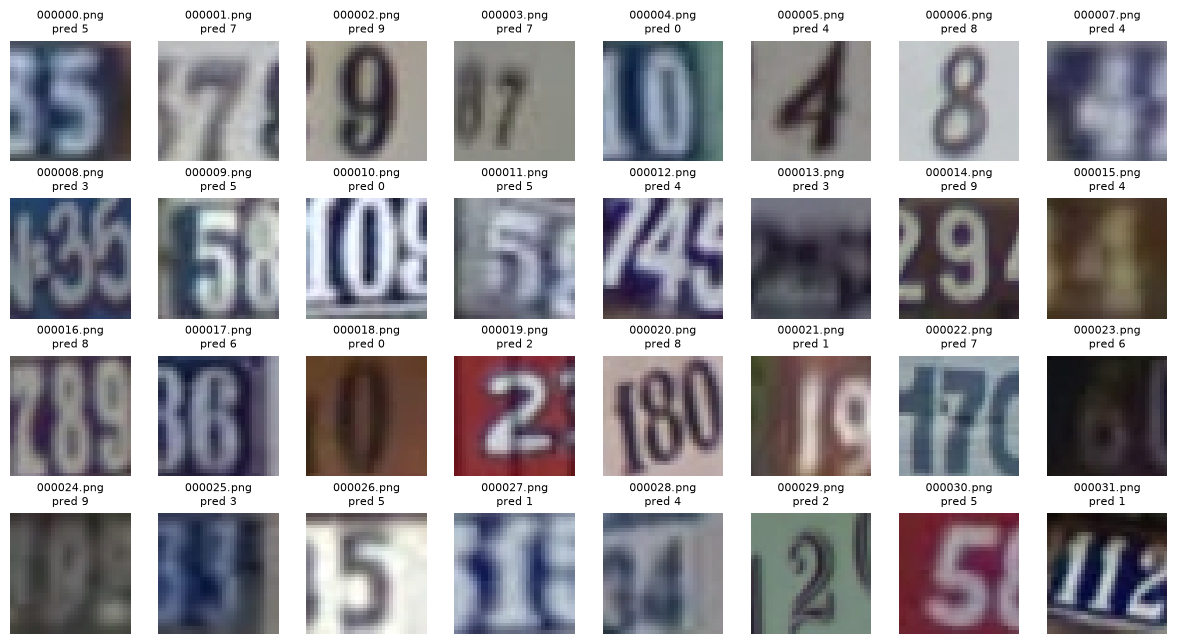

In [7]:
# inspeção visual de algumas predições
n = min(32, len(X))
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for ax, i in zip(axes.flat, range(n)):
    ax.imshow(X[i].permute(1, 2, 0)); ax.set_title(f"{names[i][:14]}\npred {preds[i]}", fontsize=8)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()